# 3W Dataset Processing & Scaling Methods

Data preprocessing for the 3W dataset - fault detection in oil wells.

## Processing Steps
- Data loading with the toolkit `ParquetDataset`, with optional sampling
- Multiple scaling methods comparison (toolkit `Normalize` and scikit-learn scalers)  
- Cross-validation with real/simulated separation (toolkit `KFoldSplitter`)
- Time windowing for sequence models (toolkit `Windowing`)
- Data persistence for training notebooks

## Configuration
All parameters managed in `src/config.py`

**Note**: this demonstration was developed using the **3W Dataset 2.0.0** and the **3W Toolkit 3.2.1**; results may differ if other versions were used.

> 📖 **Companion book** — this notebook exercises **Chapter 3** (*Os dados: séries temporais de poços e o conjunto 3W*) and the validation discussion of **Chapter 4** of Lopes et al. (2026), *Aprendizado de Mundo Aberto em Poços de Petróleo* ([DOI 10.5281/zenodo.22306796](https://doi.org/10.5281/zenodo.22306796)). **Appendix E** of the book maps every notebook of this resource to its chapters.
>
> 🧰 **3W Toolkit 3.2.1** — this notebook is built on the toolkit: the raw files are read with the official [`ParquetDataset`](../../toolkit/ThreeWToolkit/README.md), the folds come from `KFoldSplitter`, missing values are filled by `ImputeMissing`, the default scaler is `Normalize` and the windows are produced by `Windowing` (see the [3W Toolkit v2.0.0 tutorial](../introduction_to_3w_toolkit_v2.0.0/README.md)). Each step shows the toolkit first. What stays in `src/` is what the toolkit does not have: the cleaning and downsampling of each event, a view of in-memory events for `Normalize.fit`, the repacking of the windows (`src/events.py`) and the persistence of the processed data. The scikit-learn scalers `standard`, `minmax` and `robust` (fitted per event) are only alternatives, and the *train on real + simulated, test on real only* policy is written in this notebook, on top of `KFoldSplitter`.

In [1]:
# Import the course helpers and the configuration
import pandas as pd
import ThreeWToolkit

from src import config
from src.data_persistence import DataPersistence
from src.events import InMemoryEvents, clean_event, windows_to_frames
from src.visualization import plot_dataset_overview

print(
    f"3W Toolkit {ThreeWToolkit.__version__} "
    f"(the results of this resource were measured with {config.EXPECTED_TOOLKIT_VERSION})"
)
if ThreeWToolkit.__version__ != config.EXPECTED_TOOLKIT_VERSION:
    print("⚠️ A different version of the toolkit is installed: the results may differ from the ones in this resource.")

print("3W Dataset Processing Methods Loaded")
print(
    f"Configuration: Target features: {len(config.TARGET_FEATURES)}, "
    f"Scaling: {config.DEFAULT_SCALING_METHOD}, "
    f"CV folds: {config.N_FOLDS}, "
    f"Window: {config.WINDOW_SIZE} (overlap {config.WINDOW_OVERLAP})"
)
if config.ENABLE_DATA_SAMPLING:
    print(f"Data sampling: 1/{config.SAMPLING_RATE} ({config.SAMPLING_METHOD})")
print(f"🎲 Random seed: {config.RANDOM_SEED}")

3W Toolkit 3.2.1 (the results of this resource were measured with 3.2.1)
3W Dataset Processing Methods Loaded
Configuration: Target features: 4, Scaling: normalizer, CV folds: 3, Window: 300 (overlap 0.5)
Data sampling: 1/5 (uniform)
🎲 Random seed: 42


**Data treatment** is the foundation of any successful ML pipeline. Raw sensor data from oil wells contains:
- **Noise** and measurement errors
- **Missing values** from sensor failures  
- **Scale differences** between variables (pressure in bar vs temperature in °C)
- **Temporal dependencies** requiring sequence modeling

**Key Steps:**
1. **Loading & Exploration** - Understanding data structure and quality
2. **Feature Selection** - Focusing on relevant sensors  
3. **Scaling/Normalization** - Making variables comparable
4. **Cross-validation** - Ensuring robust model evaluation
5. **Windowing** - Creating sequences for time-series models

## Data Loading & Exploration

**Why explore first?**
- **Understanding structure** - How many classes, samples per class
- **Quality assessment** - Missing values, outliers, data integrity
- **Planning strategies** - Choosing appropriate preprocessing methods

**3W Dataset specifics:**
- **Multivariate time series** from oil well sensors
- **Multiple fault types** (0=normal, 1-8=different faults)  
- **Real vs simulated** data with different characteristics

> 📖 **In the book — Chapter 3, §*Três procedências* and §*A rotulação*.** Every 3W instance is *real* (`WELL-*`), *simulated* (`SIMULATED-*`) or *hand-drawn* (`DRAWN-*`), and the label is given per instance. Mixing the three without declaring it is the most common way of inflating results. Here, the loading cell takes real events first and then fills the per-class limit with `config.NON_REAL_EVENT_TYPES` (simulated **and** drawn, to keep the historical behaviour of this resource). The book's reproduction protocol (**Appendix D**) is stricter — it never uses drawn events and uses simulated ones only for classes with few real instances — and you can approximate it with `NON_REAL_EVENT_TYPES = ["simulated"]`.

## Dataset Loading

Load the 3W dataset and explore structure.

### Toolkit first: `ParquetDataset`

The 3W Toolkit opens the dataset for us. `ParquetDataset` lists the event files, downloads the dataset when it is missing (version 2.0.0), filters by provenance (`event_type`: `real`, `simulated`, `drawn`) and by class (`target_class`), keeps only the sensors we ask for (`columns`) and returns **one event per item**, with its metadata (`file_name`, `event_class`, `event_type`).

The toolkit also has an interactive, class-shaded Plotly view of one file, `ThreeWChart` (toolkit demo 14). Here we use the static `PlotMultipleSeries` and `CorrelationHeatmap`, which keep the notebook light.

2026-11-05 11:27:24,060 | INFO | ThreeWToolkit.dataset.parquet_dataset | Dataset found at ..\..\dataset


2026-11-05 11:27:24,062 | INFO | ThreeWToolkit.dataset.parquet_dataset | Validating dataset integrity...


2026-11-05 11:27:24,062 | INFO | ThreeWToolkit.dataset.parquet_dataset | Dataset integrity check passed!


2026-11-05 11:27:24,230 | INFO | ThreeWToolkit.dataset.parquet_dataset | Dataset found at ..\..\dataset


2026-11-05 11:27:24,234 | INFO | ThreeWToolkit.dataset.parquet_dataset | Validating dataset integrity...


2026-11-05 11:27:24,235 | INFO | ThreeWToolkit.dataset.parquet_dataset | Dataset integrity check passed!


... (5 outputs left out)

2026-11-05 11:27:24,698 | INFO | ThreeWToolkit.dataset.parquet_dataset | Dataset found at ..\..\dataset


2026-11-05 11:27:24,698 | INFO | ThreeWToolkit.dataset.parquet_dataset | Validating dataset integrity...


2026-11-05 11:27:24,698 | INFO | ThreeWToolkit.dataset.parquet_dataset | Dataset integrity check passed!



Metadata: {'file_name': WindowsPath('3/WELL-00001_20170320120025.parquet'), 'event_class': 3, 'event_type': 'real'}
Signal: (21576, 3) | Label: (21576,)


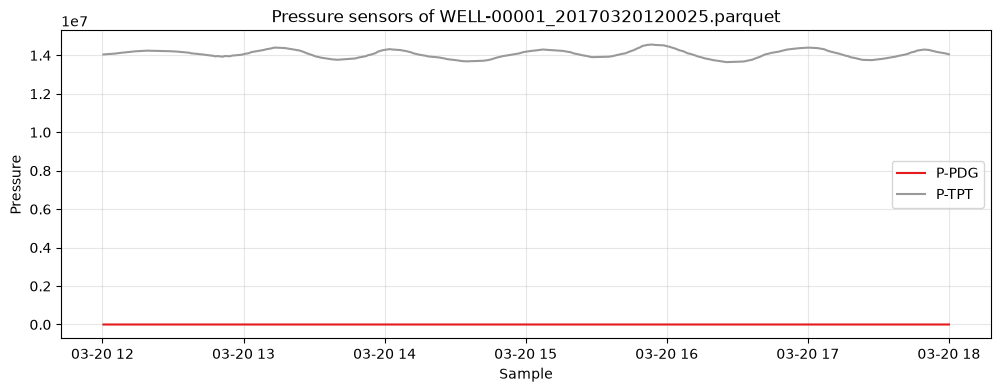

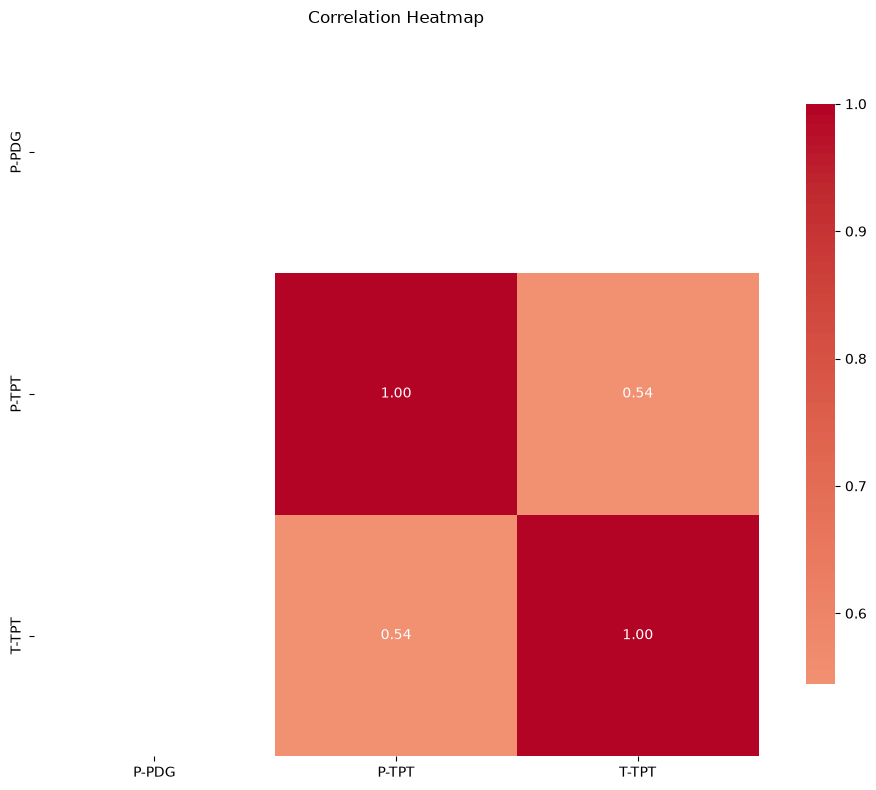

In [2]:
# Toolkit first: open the events and look at one of them
import matplotlib.pyplot as plt
from ThreeWToolkit.dataset import ParquetDataset, ParquetDatasetConfig
from ThreeWToolkit.data_visualization import CorrelationHeatmap, PlotMultipleSeries

sensors = [c for c in config.TARGET_FEATURES if c != config.CLASS_COLUMN]

# How many events of each provenance does the dataset have?
for provenance in ("real", "simulated", "drawn"):
    events = ParquetDataset(
        ParquetDatasetConfig(
            path="../../dataset/",
            event_type=[provenance],
            columns=sensors,
            target_column=config.CLASS_COLUMN,
        )
    )
    print(f"{provenance:>9}: {len(events)} events")

# One event: signal (DataFrame), label (Series) and metadata
real_events = ParquetDataset(
    ParquetDatasetConfig(
        path="../../dataset/",
        event_type=["real"],
        target_class=[3],
        columns=sensors,
        target_column=config.CLASS_COLUMN,
    )
)
event = real_events[0]
print("\nMetadata:", event.metadata)
print("Signal:", event.signal.shape, "| Label:", event.label.shape)

pressures = [s for s in sensors if s.startswith("P-")]
fig, ax = plt.subplots(figsize=(12, 4))
PlotMultipleSeries(
    series_list=[event.signal[s] for s in pressures],
    labels=pressures,
    title=f"Pressure sensors of {event.metadata['file_name'].name}",
    xlabel="Sample",
    ylabel="Pressure",
).plot(ax=ax)
plt.show()

CorrelationHeatmap(event.signal[sensors].dropna(), annot=True, cmap="coolwarm").plot()
plt.show()

### Choosing the events: `ParquetDataset` plus a limit per class

`ParquetDataset` has no cap per class and no downsampling, so the next cell does both in a few lines. For each class it takes up to `MAX_FILES_PER_CLASS` events, **real ones first** and then the provenances of `config.NON_REAL_EVENT_TYPES`. Each event is read with `ParquetDataset` and cleaned with `clean_event` (`src/events.py`): rows without a label are dropped, one row in every `SAMPLING_RATE` is kept and the gaps are filled. An event with a sensor that is entirely missing is discarded.

2026-11-05 11:27:26,488 | INFO | ThreeWToolkit.dataset.parquet_dataset | Dataset found at ..\..\dataset


2026-11-05 11:27:26,488 | INFO | ThreeWToolkit.dataset.parquet_dataset | Validating dataset integrity...


2026-11-05 11:27:26,488 | INFO | ThreeWToolkit.dataset.parquet_dataset | Dataset integrity check passed!


2026-11-05 11:27:26,633 | INFO | ThreeWToolkit.dataset.parquet_dataset | Dataset found at ..\..\dataset


2026-11-05 11:27:26,633 | INFO | ThreeWToolkit.dataset.parquet_dataset | Validating dataset integrity...


2026-11-05 11:27:26,633 | INFO | ThreeWToolkit.dataset.parquet_dataset | Dataset integrity check passed!


   real_available  other_available  real_loaded  other_loaded
0             594                0           50             0
1               4              124            4            46
2              22               16           21            16
3              32               74           32            18
4             343                0           50             0
5              11              439           11            39
6               6              215            6             0
7              36               10           31            10
8              14               81            8            36
9              57              150           22             0

Maximum 50 files per class (prioritizing real data)
Loaded 235 real and 165 simulated/drawn events (84 discarded: a sensor entirely missing)


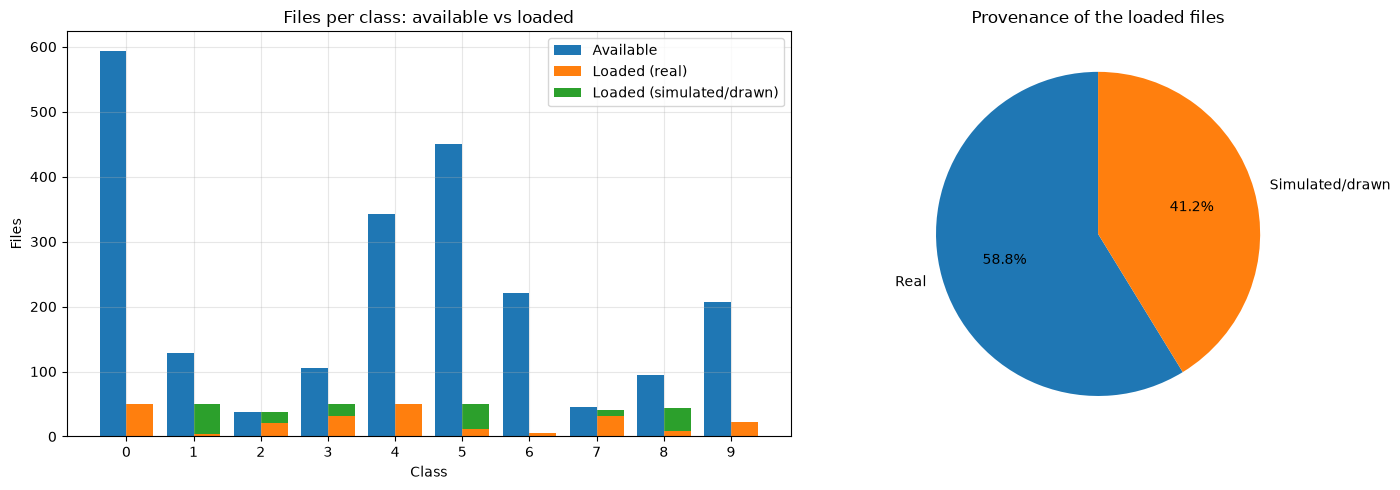

In [3]:
# Step 1: Choose the events (up to MAX_FILES_PER_CLASS per class, real first) and load them
from collections import Counter


def open_events(event_types):
    return ParquetDataset(
        ParquetDatasetConfig(
            path="../../dataset/",
            event_type=event_types,
            target_class=list(range(10)),
            columns=config.TARGET_FEATURES,  # the sensors and the label column
            target_column=None,
        )
    )


def positions_by_class(events):
    '''Class folder -> positions of its events in the dataset.'''
    positions = {}
    for position, file in enumerate(events.files_events):
        positions.setdefault(file.parent.name, []).append(position)
    return positions


real_events = open_events(["real"])
other_events = open_events(config.NON_REAL_EVENT_TYPES)
real_positions = positions_by_class(real_events)
other_positions = positions_by_class(other_events)
class_folders = sorted(real_positions.keys() | other_positions.keys())

loaded = {"real": [], "other": []}  # (class, file, dataframe) of every event kept
discarded = 0
for class_folder in class_folders:
    chosen_real = real_positions.get(class_folder, [])[: config.MAX_FILES_PER_CLASS]
    room = config.MAX_FILES_PER_CLASS - len(chosen_real)
    chosen_other = other_positions.get(class_folder, [])[:room]
    for kind, events, positions in (
        ("real", real_events, chosen_real),
        ("other", other_events, chosen_other),
    ):
        for position in positions:
            df = clean_event(events[position].signal)
            if df is None:
                discarded += 1
            else:
                loaded[kind].append((class_folder, events.files_events[position], df))

counts = pd.DataFrame(
    {
        "real_available": [len(real_positions.get(c, [])) for c in class_folders],
        "other_available": [len(other_positions.get(c, [])) for c in class_folders],
        "real_loaded": [sum(k == c for k, _, _ in loaded["real"]) for c in class_folders],
        "other_loaded": [sum(k == c for k, _, _ in loaded["other"]) for c in class_folders],
    },
    index=class_folders,
)
print(counts.to_string())
print(f"\nMaximum {config.MAX_FILES_PER_CLASS} files per class (prioritizing real data)")
print(
    f"Loaded {counts.real_loaded.sum()} real and {counts.other_loaded.sum()} "
    f"simulated/drawn events ({discarded} discarded: a sensor entirely missing)"
)
plot_dataset_overview(counts)

## Feature Selection

**Why feature selection matters:**
- **Availability** - Missing features require more complex treatment to be used
- **Curse of dimensionality** - Too many features can hurt performance
- **Computational efficiency** - Fewer features = faster training
- **Domain knowledge** - Focus on physically meaningful sensors

**Oil well monitoring:**
- **Pressure sensors** indicate flow conditions and blockages
- **Temperature sensors** detect thermal anomalies and hydrates
- **Combined analysis** reveals complex fault patterns

## Feature Filtering

Filter dataset to target sensor variables.

In [4]:
# Step 2: The sensors were chosen when the events were opened (columns=config.TARGET_FEATURES)
real_files = [file for _, file, _ in loaded["real"]]
real_dfs = [df for _, _, df in loaded["real"]]
real_classes = [cls for cls, _, _ in loaded["real"]]
sim_dfs = [df for _, _, df in loaded["other"]]
sim_classes = [cls for cls, _, _ in loaded["other"]]
all_dfs = real_dfs + sim_dfs
all_classes = real_classes + sim_classes

print(f"Events kept: {len(all_dfs)} ({len(real_dfs)} real + {len(sim_dfs)} simulated/drawn)")
print(f"Columns: {list(all_dfs[0].columns)}")
print(f"Class distribution: {dict(sorted(Counter(all_classes).items()))}")
print(f"Total samples: {sum(len(df) for df in all_dfs):,}")
print(
    f"Memory: {sum(df.memory_usage(deep=True).sum() for df in all_dfs) / 1024**2:.0f} MB"
)

Events kept: 400 (235 real + 165 simulated/drawn)
Columns: ['P-PDG', 'P-TPT', 'T-TPT', 'class']
Class distribution: {'0': 50, '1': 50, '2': 37, '3': 50, '4': 50, '5': 50, '6': 6, '7': 41, '8': 44, '9': 22}
Total samples: 4,343,666


Memory: 112 MB


## Raw Data Analysis

**Why analyze raw data?**
- **Baseline understanding** - See natural patterns and variations
- **Scale assessment** - Understand magnitude differences between features
- **Quality check** - Identify obvious issues before preprocessing

**Time series characteristics:**
- **Trends** - Long-term directional changes
- **Seasonality** - Periodic patterns  
- **Noise** - Random fluctuations that need filtering
- **Anomalies** - Unusual patterns indicating faults

> 📖 **In the book — Chapter 3, §*As armadilhas*.** Three traps are visible already in the raw series: **(i)** missing values are forward/backward filled here, as in the book, but a *frozen* sensor produces a constant value, not a `NaN`, and only an explicit check of the standard deviation catches it; **(ii)** the correlation between sensors depends on the valve configuration, which 3W does not distribute; **(iii)** in several classes (notably 2, 6, 7 and 8) the onset of the anomaly coincides with the loss of the downhole gauges (`P-PDG`, `T-PDG`) — a model can learn *"the downhole sensors vanished, so it is an anomaly"*, a rule that scores well and is useless in operation. Keep this in mind when you interpret any result obtained with `P-PDG`.

Sample event: class 3, 3596 samples
      P-PDG        P-TPT   T-TPT
min     0.0  13645510.00  116.21
max     0.0  14563020.00  117.81
mean    0.0  14062884.60  117.01
std     0.0    234365.41    0.35


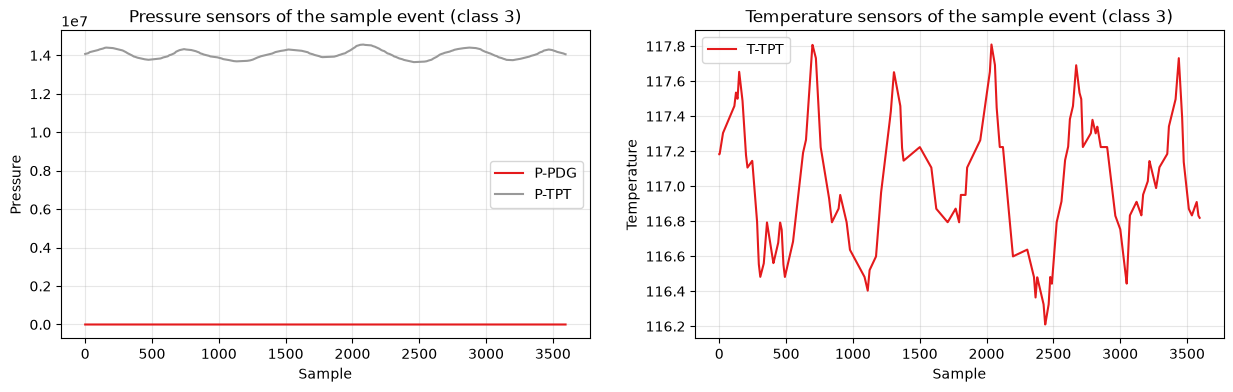

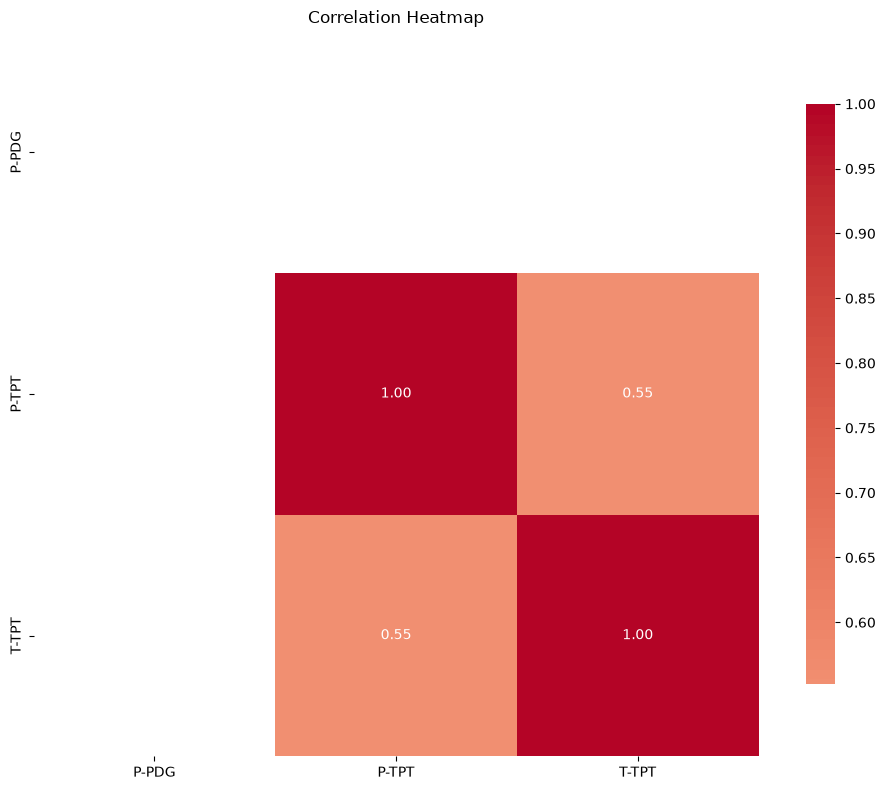

In [5]:
# Step 3: Raw data analysis of one real event of class 3
sample_df, class_label = next((df, cls) for cls, _, df in loaded["real"] if cls == "3")
print(f"Sample event: class {class_label}, {len(sample_df)} samples")
print(sample_df[sensors].describe().loc[["min", "max", "mean", "std"]].round(2))

# PlotMultipleSeries draws on the axis it receives, so the plots can share a figure
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, (group, quantity) in zip(
    axes,
    (
        ([s for s in sensors if s.startswith("P-")], "Pressure"),
        ([s for s in sensors if s.startswith("T-")], "Temperature"),
    ),
):
    PlotMultipleSeries(
        series_list=[sample_df[s] for s in group],
        labels=group,
        title=f"{quantity} sensors of the sample event (class {class_label})",
        xlabel="Sample",
        ylabel=quantity,
    ).plot(ax=ax)
plt.show()

CorrelationHeatmap(sample_df[sensors], annot=True, cmap="coolwarm").plot()
plt.show()

## Data Scaling Theory

**Why scaling is crucial:**
- **Different scales** - Pressure (0-100 bar) vs Temperature (20-80°C)
- **Algorithm bias** - Distance-based algorithms favor larger-scale features
- **Gradient descent** - Converges faster with normalized inputs

**Common scaling methods:**
- **`Normalize` (toolkit)** - Centers each sensor and divides by a dispersion measure (L2 by default, i.e. a z-score; L1 or max are also available). Its statistics are collected over *all* the events it is fitted on
- **MinMax [0,1]** - Preserves relationships, good for bounded data
- **StandardScaler** - Centers data, good for normal distributions  
- **RobustScaler** - Less sensitive to outliers

**Choosing the right scaler depends on data distribution and algorithm requirements.**

> 📖 **In the book — Chapter 3, §*Pré-processamento*.** The book uses **Min-Max** where the autoencoder has a sigmoid output (Chapter 7) and **standardization** (z-score) where the model assumes roughly Gaussian data, as in the Mahalanobis distance (Chapter 12). It also stresses that *the set used to fit each transformation matters*: the book fits the scaler on training data only. In this notebook the default is the toolkit `Normalize`, fitted on the **training events of each fold only** and applied to the test events, as the book recommends. The scikit-learn scalers (`standard`, `minmax`, `robust`) are kept as alternatives and are fitted on **each event separately** (`fit_transform` per dataframe), which is simple and removes absolute levels. The sigmoid autoencoder of notebook 3 needs inputs in [0, 1], so that notebook rescales the normal windows with Min-Max after this step — exercise 1 at the end of this notebook asks you to compare the effect of the four methods.

Scaling Results:


Normalizer (toolkit):
  P-PDG - Range: [0.0000, 0.0000]
  P-TPT - Range: [-1.7811, 2.1343]
  T-TPT - Range: [-2.3014, 2.2899]
StandardScaler:
  P-PDG - Range: [0.0000, 0.0000]
  P-TPT - Range: [-1.7811, 2.1343]
  T-TPT - Range: [-2.3014, 2.2899]
MinMaxScaler:
  P-PDG - Range: [0.0000, 0.0000]
  P-TPT - Range: [0.0000, 1.0000]
  T-TPT - Range: [0.0000, 1.0000]
RobustScaler:
  P-PDG - Range: [0.0000, 0.0000]
  P-TPT - Range: [-1.0735, 1.2570]
  T-TPT - Range: [-1.6615, 1.6561]


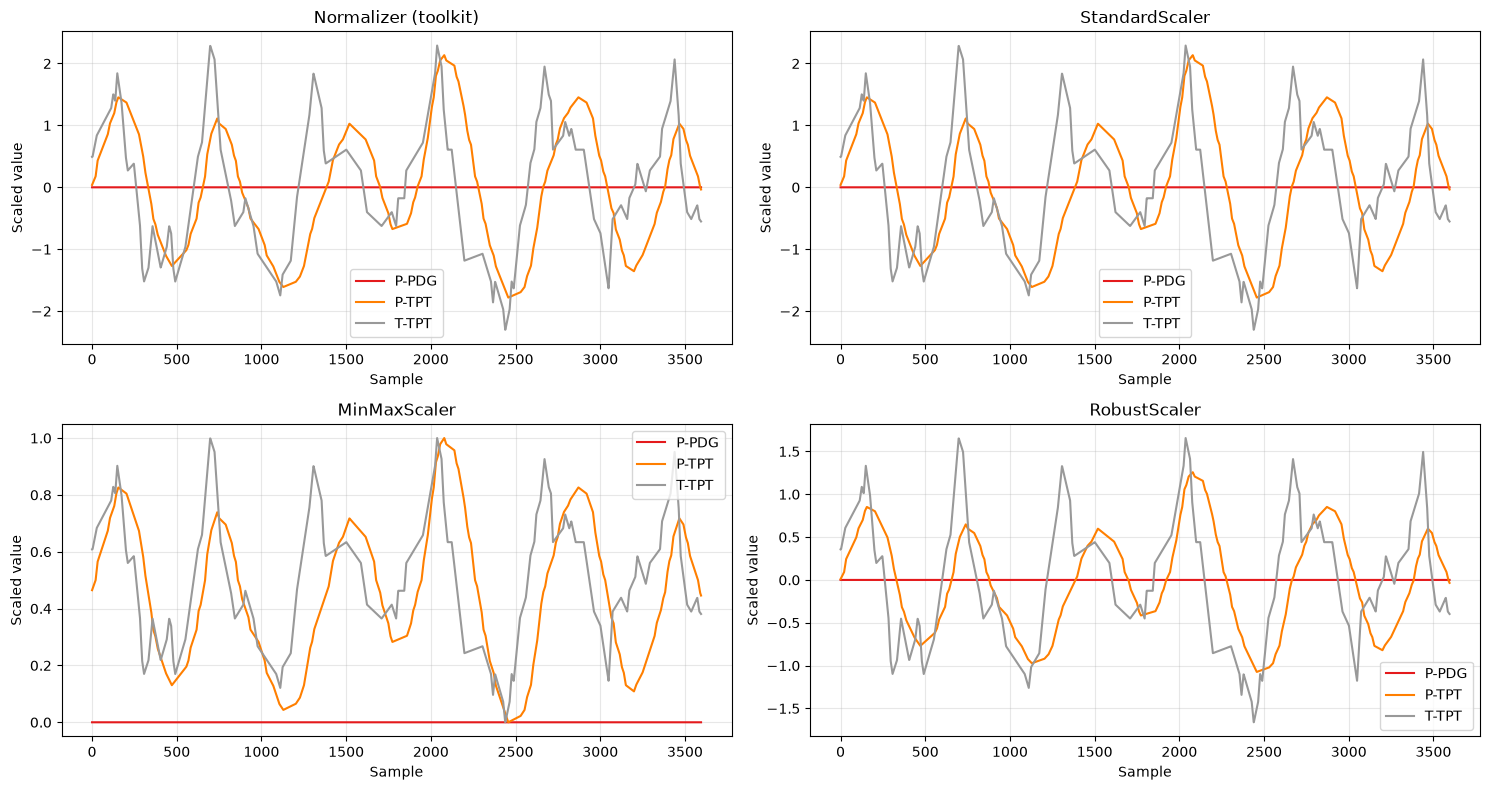

In [6]:
# Step 4: Scaling methods comparison on the sample event
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler
from ThreeWToolkit.core.dataset_outputs import DatasetOutputs
from ThreeWToolkit.preprocessing import NormalizeConfig

sample = sample_df[sensors]

# Toolkit first: Normalize collects a mean and a dispersion per sensor
normalizer = NormalizeConfig(norm=config.NORMALIZE_NORM, exclude_features=[]).build()
normalizer.fit(InMemoryEvents([sample]))
scaled = {
    "Normalizer (toolkit)": normalizer.transform(
        DatasetOutputs(signal=sample, label=None, metadata={})
    ).signal
}
# The scikit-learn scalers, fitted on the event itself
for name, scaler in {
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "RobustScaler": RobustScaler(),
}.items():
    scaled[name] = pd.DataFrame(scaler.fit_transform(sample), columns=sensors)

print("Scaling Results:")
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
for ax, (name, data) in zip(axes.ravel(), scaled.items()):
    print(f"{name}:")
    for sensor in sensors:
        print(f"  {sensor} - Range: [{data[sensor].min():.4f}, {data[sensor].max():.4f}]")
    PlotMultipleSeries(
        series_list=[data[s] for s in sensors],
        labels=sensors,
        title=name,
        xlabel="Sample",
        ylabel="Scaled value",
    ).plot(ax=ax)
plt.tight_layout()
plt.show()

## Choose the Scaler

Pick the configured scaling method and check it on the sample event. The scaling itself is applied **after** the cross-validation split, fold by fold.

**Implementation strategy:**
- **Fit on training data only** - the toolkit `Normalize` collects its statistics from the training events of a fold
- **Transform both train and test** with the same fitted step
- **Validation** - Check scaling worked correctly

**Missing values:** the toolkit `ImputeMissing` forward/backward fills each event before the normalization.

In [7]:
# Step 5: Choose the scaler and check it on the sample event
print("🔄 Step 5: Choosing the Configured Scaler")

scaling_method = config.DEFAULT_SCALING_METHOD
print(f"Using scaling method from config: {scaling_method}")

method_names = {
    "normalizer": "Normalizer (toolkit)",
    "standard": "StandardScaler",
    "minmax": "MinMaxScaler",
    "robust": "RobustScaler",
}
print(scaled[method_names[scaling_method]].describe().loc[["min", "max", "mean", "std"]].round(3))

print("The whole dataset is scaled after the split, fold by fold:")
print(f"   • {scaling_method}: statistics from the training events of each fold")
print("   • all other events of the fold use those same statistics")

🔄 Step 5: Choosing the Configured Scaler
Using scaling method from config: normalizer
      P-PDG  P-TPT  T-TPT
min     0.0 -1.781 -2.301
max     0.0  2.134  2.290
mean    0.0  0.000 -0.000
std     0.0  1.000  1.000
The whole dataset is scaled after the split, fold by fold:
   • normalizer: statistics from the training events of each fold
   • all other events of the fold use those same statistics


## Cross-Validation Theory

**Why cross-validation?**
- **Model generalization** - Ensure performance on unseen data
- **Avoiding overfitting** - Test on multiple data splits
- **Robust evaluation** - Average performance across folds

**Special considerations for time series:**
- **Temporal order** - Can't randomly shuffle time-dependent data
- **Real vs simulated** - Different data characteristics require careful splitting
- **Realistic evaluation** - Test on real data, train on both real + simulated

**3W Strategy:**
- **Training set** - All available data (real + simulated)
- **Test set** - Real data only (more challenging, realistic)
- **Cross-validation** - Multiple folds for robust estimates

> 📖 **In the book — Chapter 3, §*Vazamento temporal e vazamento entre poços* and Chapter 4, §*Validação*.** Overlapping windows of the same instance spread across train and test make the model memorize; windows of the same well on both sides make it learn the well instead of the event. This resource avoids the first problem by **splitting by instance (file), not by window**. The policy *train on real + simulated, test on real only* is defensible, but it differs from the book (temporal 80/20 split inside each instance, or well-by-well evaluation, which exposes the between-well variability that an average hides). Comparing both policies is a good exercise (see the end of the notebook).

## Cross-Validation Implementation

**Toolkit first:** `KFoldSplitter` splits a dataset of **events** (one item per file), optionally stratified by a metadata key such as `event_class`. Because the unit is the event, windows of the same instance never end up on both sides of a split.

**Fold creation process:**
1. **Split the real events** with `KFoldSplitter`, stratified by class
2. **Apply the 3W policy** - every fold trains on its real events plus all the simulated/drawn ones and is tested on its real events only
3. **Scale each fold** with statistics of its training events only

**Key metrics to monitor:**
- **Class balance** across folds
- **Real/simulated ratio** in training sets
- **Sample sizes** for statistical significance

In [8]:
# Toolkit only: K-fold over the real events, stratified by class
from ThreeWToolkit.utils import KFoldSplitter

splitter = KFoldSplitter(
    num_splits=config.N_FOLDS,
    random_state=config.CV_RANDOM_STATE,
    stratify_by=["event_class"],
)

# The real events kept above, in the same order as `real_dfs`
kept_real_events = ParquetDataset(
    ParquetDatasetConfig(
        path="../../dataset/",
        split="list",
        file_list=real_files,
        event_type=["real"],
        columns=config.TARGET_FEATURES,
        target_column=None,
    )
)
assert list(kept_real_events.files_events) == real_files

splits = list(splitter.split_data(kept_real_events))
for fold, (train_events, test_events) in enumerate(splits, 1):
    test_per_class = Counter(real_classes[i] for i in test_events.indices)
    print(
        f"Fold {fold}: {len(train_events)} train / {len(test_events)} test real events | "
        f"test per class: {dict(sorted(test_per_class.items()))}"
    )

2026-11-05 11:27:58,470 | INFO | ThreeWToolkit.dataset.parquet_dataset | Dataset found at ..\..\dataset


2026-11-05 11:27:58,470 | INFO | ThreeWToolkit.dataset.parquet_dataset | Validating dataset integrity...


2026-11-05 11:27:58,470 | INFO | ThreeWToolkit.dataset.parquet_dataset | Dataset integrity check passed!


Fold 1: 156 train / 79 test real events | test per class: {'0': 17, '1': 1, '2': 7, '3': 11, '4': 17, '5': 3, '6': 2, '7': 11, '8': 2, '9': 8}
Fold 2: 157 train / 78 test real events | test per class: {'0': 17, '1': 1, '2': 7, '3': 11, '4': 16, '5': 4, '6': 2, '7': 10, '8': 3, '9': 7}
Fold 3: 157 train / 78 test real events | test per class: {'0': 16, '1': 2, '2': 7, '3': 10, '4': 17, '5': 4, '6': 2, '7': 10, '8': 3, '9': 7}


In [9]:
# Step 5b: Build the folds and scale each one with the statistics of its training events
from ThreeWToolkit.preprocessing import ImputeMissingConfig

imputer = ImputeMissingConfig(strategy="ffill").build()
SKLEARN_SCALERS = {
    "standard": StandardScaler,
    "minmax": MinMaxScaler,
    "robust": RobustScaler,
}


def scale_events(dfs, classes, normalizer=None):
    '''Scale events with the toolkit Normalize, or with a scikit-learn scaler fitted on each event.'''
    scaled_dfs, kept_classes = [], []
    for df, cls in zip(dfs, classes):
        if normalizer is not None:
            try:
                event = imputer.transform(
                    DatasetOutputs(signal=df[sensors], label=None, metadata={})
                )
            except RuntimeError:  # a sensor without any valid value: skip the event
                continue
            scaled = normalizer.transform(event).signal
        else:
            scaler = SKLEARN_SCALERS[scaling_method]()
            scaled = pd.DataFrame(
                scaler.fit_transform(df[sensors]), columns=sensors, index=df.index
            )
        scaled = scaled.rename(columns=lambda c: f"{c}_scaled")
        scaled[config.CLASS_COLUMN] = df[config.CLASS_COLUMN]
        scaled_dfs.append(scaled)
        kept_classes.append(cls)
    return scaled_dfs, kept_classes


cv_folds = []
for fold_number, (train_events, test_events) in enumerate(splits, 1):
    # 3W policy: train on the real events of the fold plus all the simulated/drawn ones,
    # test on the real events of the fold only
    train_dfs = [real_dfs[i] for i in train_events.indices] + sim_dfs
    train_classes = [real_classes[i] for i in train_events.indices] + sim_classes
    test_dfs = [real_dfs[i] for i in test_events.indices]
    test_classes = [real_classes[i] for i in test_events.indices]

    normalizer = None
    if scaling_method == "normalizer":
        normalizer = NormalizeConfig(norm=config.NORMALIZE_NORM, exclude_features=[]).build()
        normalizer.fit(InMemoryEvents([df[sensors] for df in train_dfs]))

    train_dfs, train_classes = scale_events(train_dfs, train_classes, normalizer)
    test_dfs, test_classes = scale_events(test_dfs, test_classes, normalizer)
    cv_folds.append(
        {
            "fold_number": fold_number,
            "train_dfs": train_dfs,
            "train_classes": train_classes,
            "test_dfs": test_dfs,
            "test_classes": test_classes,
        }
    )
    print(
        f"Fold {fold_number}: {len(train_dfs)} train "
        f"({len(train_events)} real + {len(sim_dfs)} simulated/drawn), {len(test_dfs)} test"
    )
print(f"\nFolds scaled with '{scaling_method}'")

Fold 1: 321 train (156 real + 165 simulated/drawn), 79 test


Fold 2: 322 train (157 real + 165 simulated/drawn), 78 test


Fold 3: 322 train (157 real + 165 simulated/drawn), 78 test

Folds scaled with 'normalizer'


## Time Windowing Theory

**Why windowing for time series?**
- **Sequential dependencies** - Capture temporal patterns and trends
- **Fixed input size** - Most ML algorithms require consistent input dimensions
- **Pattern recognition** - Enable detection of temporal fault signatures

**Windowing parameters:**
- **Window size** - How much history to include (e.g., 100 time steps)
- **Overlap** - Fraction of a window shared with the next one (0 = non-overlapping)

**Benefits:**
- **LSTM/RNN compatibility** - Sequential models need windowed data
- **Pattern extraction** - Capture fault development over time
- **Data augmentation** - Generate more training samples from limited data

**Trade-offs:**
- **Larger windows** - More context but higher memory usage
- **Larger overlap** - More samples but increased correlation between windows

> 📖 **In the book — Chapter 3 (leakage) and Appendix E (§*Configuração central*).** Two settings of `src/config.py` change the nature of the experiment: **`SAMPLING_RATE = 5`** keeps one row in five, so a 300-point window covers 1500 s of operation instead of 300 s (compare with the book by *time covered*, not by number of points); **`WINDOW_OVERLAP = 0.5`** gives 50 % overlap (windows 150 samples apart), harmless here only because folds are built per instance. 
>
> 🧰 The windowing below is done by the toolkit [`Windowing`](../../toolkit/ThreeWToolkit/feature_extraction/windowing.py) step (fractional `overlap`, window functions, `last`/`mode` labels). It is called once per event, with `pad_start=False` so that only complete windows are produced (an event shorter than the window gives none). `windows_to_frames` (`src/events.py`) rebuilds one dataframe per window, with the label column of the event.

In [10]:
# Toolkit only: the Windowing step on one event of fold 1
from ThreeWToolkit.feature_extraction import WindowingConfig

windowing = WindowingConfig(
    window_size=config.WINDOW_SIZE,
    overlap=config.WINDOW_OVERLAP,
    pad_start=False,  # only complete windows
    label_strategy="last",
).build()

one_event = cv_folds[0]["train_dfs"][0].drop(columns=config.CLASS_COLUMN)
windowed = windowing.transform(
    DatasetOutputs(signal=one_event, label=None, metadata={})
)
print(f"Event: {one_event.shape} -> windowed signal: {windowed.signal.shape}")
print("Index levels:", windowed.signal.index.names, "| columns = time steps inside the window")
windowed.signal.head(6)

Event: (3586, 3) -> windowed signal: (66, 300)
Index levels: ['window', 'variable'] | columns = time steps inside the window


0         1         2         3         4    \
window variable                                                         
0      P-PDG_scaled  0.097503  0.097503  0.097503  0.097503  0.097503   
       P-TPT_scaled -0.055042 -0.055042 -0.055042 -0.055042 -0.055042   
       T-TPT_scaled  1.060005  1.059990  1.059977  1.059965  1.059949   
1      P-PDG_scaled  0.097503  0.097503  0.097503  0.097503  0.097503   
       P-TPT_scaled -0.054846 -0.054846 -0.054846 -0.054846 -0.054846   
       T-TPT_scaled  1.058797  1.058817  1.058837  1.058857  1.058877   

                          5         6         7         8         9    ...  \
window variable                                                        ...   
0      P-PDG_scaled  0.097503  0.097503  0.097503  0.097503  0.097503  ...   
       P-TPT_scaled -0.055042 -0.055042 -0.055042 -0.055042 -0.055042  ...   
       T-TPT_scaled  1.059937  1.059924  1.059909  1.059897  1.059884  ...   
1      P-PDG_scaled  0.097503  0.097503  0.097503  0.097503  0.097503  ...   
       P-TPT_scaled -0.054846 -0.054846 -0.054846 -0.054846 -0.054846  ...   
       T-TPT_scaled  1.058895  1.058915  1.058935  1.058956  1.058976  ...   

                          290       291       292       293       294  \
window variable                                                         
0      P-PDG_scaled  0.097503  0.097503  0.097503  0.097503  0.097503   
       P-TPT_scaled -0.054772 -0.054767 -0.054763 -0.054758 -0.054753   
       T-TPT_scaled  1.058978  1.058988  1.058998  1.059006  1.059016   
1      P-PDG_scaled  0.097503  0.097503  0.097503  0.097503  0.097503   
       P-TPT_scaled -0.054650 -0.054650 -0.054650 -0.054650 -0.054650   
       T-TPT_scaled  1.060411  1.060421  1.060431  1.060441  1.060449   

                          295       296       297       298       299  
window variable                                                        
0      P-PDG_scaled  0.097503  0.097503  0.097503  0.097503  0.097503  
       P-TPT_scaled -0.054749 -0.054744 -0.054739 -0.054735 -0.054730  
       T-TPT_scaled  1.059026  1.059036  1.059044  1.059054  1.059064  
1      P-PDG_scaled  0.097503  0.097503  0.097503  0.097503  0.097503  
       P-TPT_scaled -0.054650 -0.054650 -0.054650 -0.054650 -0.054650  
       T-TPT_scaled  1.060459  1.060469  1.060479  1.060489  1.060497  

[6 rows x 300 columns]

In [11]:
# STEP 6: Window every event of every fold with the toolkit Windowing step
print(f"Window size: {config.WINDOW_SIZE} samples | overlap: {config.WINDOW_OVERLAP} | step: {windowing.step} samples")

all_windowed_folds = []
total_train_windows = total_test_windows = 0
for fold in cv_folds:
    windowed_fold = {"fold_number": fold["fold_number"]}
    for split in ("train", "test"):
        frames, labels = [], []
        for df, cls in zip(fold[f"{split}_dfs"], fold[f"{split}_classes"]):
            if len(df) < config.WINDOW_SIZE:  # shorter than one window: no window
                continue
            windows = windowing.transform(
                DatasetOutputs(
                    signal=df.drop(columns=config.CLASS_COLUMN), label=None, metadata={}
                )
            )
            event_frames = windows_to_frames(df, windows, config.WINDOW_SIZE, windowing.step)
            frames += event_frames
            labels += [cls] * len(event_frames)
        windowed_fold[split] = (frames, labels)
    all_windowed_folds.append(windowed_fold)
    n_train, n_test = len(windowed_fold["train"][0]), len(windowed_fold["test"][0])
    total_train_windows += n_train
    total_test_windows += n_test
    print(f"   📁 Fold {fold['fold_number']}: {n_train} train, {n_test} test windows ✅")

print("Windowing Complete:")
print(f"   • Total training windows: {total_train_windows:,}")
print(f"   • Total test windows: {total_test_windows:,}")

Window size: 300 samples | overlap: 0.5 | step: 150 samples


   📁 Fold 1: 23191 train, 5173 test windows ✅


   📁 Fold 2: 22750 train, 5614 test windows ✅


   📁 Fold 3: 23187 train, 5177 test windows ✅
Windowing Complete:
   • Total training windows: 69,128
   • Total test windows: 15,964


## Windowing Implementation

**Process overview:**
1. **Apply to each CV fold** - Maintain fold integrity
2. **Generate windows** with the toolkit `Windowing` (window size and overlap from the config)
3. **Repack** each window as a dataframe that keeps the label column

**Output structure:**
- **Windowed dataframes** - One `(300, sensors + class)` dataframe per window
- **Preserved labels** - Class information maintained for each window

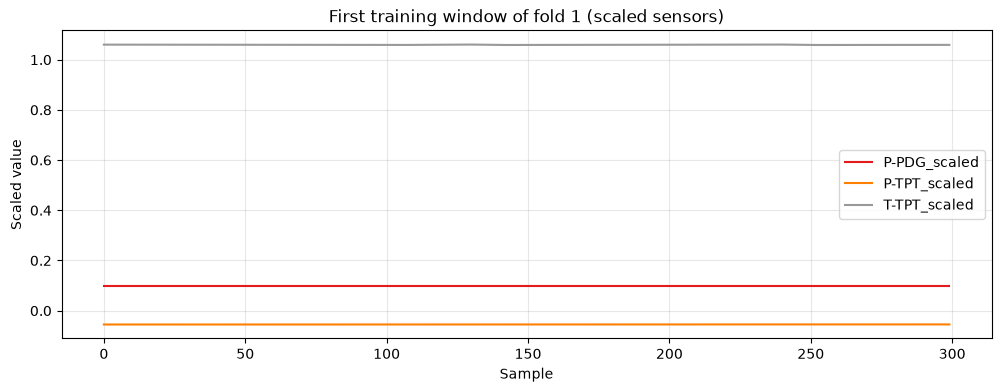

In [12]:
# Look at the first training window of fold 1
first_window = all_windowed_folds[0]["train"][0][0]
scaled_sensors = [c for c in first_window.columns if c != config.CLASS_COLUMN]
fig, ax = plt.subplots(figsize=(12, 4))
PlotMultipleSeries(
    series_list=[first_window[c] for c in scaled_sensors],
    labels=scaled_sensors,
    title="First training window of fold 1 (scaled sensors)",
    xlabel="Sample",
    ylabel="Scaled value",
).plot(ax=ax)
plt.show()

## Data Persistence Theory

**Why save processed data?**
- **Reproducibility** - Ensure consistent preprocessing across experiments
- **Efficiency** - Avoid reprocessing for multiple training runs
- **Collaboration** - Share processed data with team members
- **Version control** - Track preprocessing parameters and configurations

**Best practices:**
- **Comprehensive metadata** - Save all preprocessing parameters
- **Cross-validation integrity** - Maintain fold structure
- **Format efficiency** - Use appropriate serialization (pickle, HDF5, etc.)
- **Documentation** - Include processing timestamps and configurations

In [13]:
# STEP 7: SAVE PROCESSED DATA FOR MODEL TRAINING
print("Preparing to save:")
print(f"   • CV folds: {len(cv_folds)}")
print(f"   • Total windows: {total_train_windows + total_test_windows:,}")
print(f"   • Format: {config.SAVE_FORMAT}")
print(f"   • Directory: {config.PROCESSED_DATA_DIR}")

Preparing to save:
   • CV folds: 3
   • Total windows: 85,092
   • Format: pickle
   • Directory: processed_data


## Saving Implementation

**What gets saved:**
- **Cross-validation folds** - All train/test splits with metadata
- **Windowed data** - Time series windows ready for sequence models  
- **Processing configuration** - All parameters for reproducibility
- **Statistics** - Summary information about the processed data

**File organization:**
- **Structured directories** - Organized by processing date/time
- **Multiple formats** - Support for different ML frameworks
- **Metadata files** - Human-readable processing summaries

In [14]:
processing_config = {
    "sampling_rate": config.SAMPLING_RATE,
    "window_size": config.WINDOW_SIZE,
    "window_overlap": config.WINDOW_OVERLAP,
    "n_folds": config.N_FOLDS,
    "scaling_method": scaling_method,
    "save_format": config.SAVE_FORMAT,
    "processed_timestamp": str(pd.Timestamp.now()),
}
processing_config

{'sampling_rate': 5,
 'window_size': 300,
 'window_overlap': 0.5,
 'n_folds': 3,
 'scaling_method': 'normalizer',
 'save_format': 'pickle',
 'processed_timestamp': '2026-11-05 11:29:10.293949'}

In [15]:
# Execute Save Operation
print("🔄 Saving processed data...")

persistence = DataPersistence(base_dir=config.PROCESSED_DATA_DIR)
for fold, windowed_fold in zip(cv_folds, all_windowed_folds):
    n = fold["fold_number"]
    persistence.save_fold(
        "complete",
        n,
        (fold["train_dfs"], fold["train_classes"]),
        (fold["test_dfs"], fold["test_classes"]),
    )
    persistence.save_fold("windowed", n, windowed_fold["train"], windowed_fold["test"])
persistence.save_summary(
    {
        "processing_config": processing_config,
        "total_train_windows": total_train_windows,
        "total_test_windows": total_test_windows,
    }
)

save_summary = persistence.get_save_summary()
print(f"Saved in {config.PROCESSED_DATA_DIR}: {save_summary['total_files']} files, {save_summary['total_size_mb']:.1f} MB")
print("Ready for model training!")

🔄 Saving processed data...


   complete fold 1: 321 train, 79 test


   windowed fold 1: 23191 train, 5173 test


   complete fold 2: 322 train, 78 test


   windowed fold 2: 22750 train, 5614 test


   complete fold 3: 322 train, 78 test


   windowed fold 3: 23187 train, 5177 test
Saved in processed_data: 13 files, 1023.4 MB
Ready for model training!


In [16]:
# ============================================================
# FINAL SUMMARY
# ============================================================
print("=" * 60)
print("DATA TREATMENT PIPELINE COMPLETE!")
print("=" * 60)

print(f"Successfully processed {len(all_dfs)} samples")
print(f"Created {len(cv_folds)} cross-validation folds")
print(f"Generated {total_train_windows + total_test_windows:,} windowed samples")
print(f"Saved all data in {config.SAVE_FORMAT} format")

print("Ready for visualization and machine learning model training!")
print("Next: Visualize the saved data")

DATA TREATMENT PIPELINE COMPLETE!
Successfully processed 400 samples
Created 3 cross-validation folds
Generated 85,092 windowed samples
Saved all data in pickle format
Ready for visualization and machine learning model training!
Next: Visualize the saved data


## Pipeline Summary

**Complete data treatment pipeline:**
1. **Data loading** - Structured exploration and quality assessment
2. **Feature selection** - Domain-driven sensor focus  
3. **Cross-validation** - Robust evaluation framework (toolkit `KFoldSplitter`)
4. **Scaling** - Toolkit `Normalize`, fitted on each training fold
5. **Windowing** - Toolkit `Windowing`, time series preparation for sequence models
6. **Persistence** - Reproducible and shareable processed data

**Ready for next steps:**
- **Visualization** (notebook 2) - Data exploration and pattern analysis
- **Unsupervised learning** (notebook 3) - Anomaly detection approaches
- **Supervised learning** (notebook 4) - Classification model training
- **Clustering** (notebook 5) - Pattern discovery

## 📖 Guided exercises (book, Appendix E)

1. Run this notebook with the four scaling methods (`standard`, `minmax`, `robust`, `normalizer`) and compare the resulting distribution of each sensor. Which method best preserves the extreme values that characterize the anomalies?
2. Change `SAMPLING_RATE` from 5 to 1 (in `src/config.py`) and re-run notebooks 1 and 3. Separate the effect of the higher resolution from the effect of the change in the *time covered* by a window.
3. Implement the provenance policy of the book — exclude drawn events and include simulated ones only for scarce classes — by setting `NON_REAL_EVENT_TYPES`, and compare the results of notebook 4 under both policies.

> 📖 *Lopes et al. (2026), Appendix E — "Roteiro prático com o repositório 3W"* ([DOI 10.5281/zenodo.22306796](https://doi.org/10.5281/zenodo.22306796)).